In [1]:
import numpy as np
import pandas as pd
from scipy.stats import skew, kurtosis
from sklearn.linear_model import LinearRegression
import time
import matplotlib.pyplot as plt
import seaborn as sns

### First create one point hpi dataframe

In [2]:
one_point_country = pd.read_parquet('../data/one_point_countries_winsorized.parquet')

In [3]:
def remove_rows_by_countries(df, country_list, column="Country"):
    """
    Removes rows from the DataFrame where the value in the specified column matches any country in the list.
    Prints a message if any country in the list is not found.

    Parameters:
    - df: Original DataFrame.
    - country_list: List of country names to remove.
    - column: Name of the column containing country names (default is 'Country').

    Returns:
    - DataFrame without the rows corresponding to those countries.
    """
    df = df.copy()
    existing_countries = set(df[column].dropna().astype(str).unique())
    not_found = [country for country in country_list if country not in existing_countries]

    if not_found:
        print(f"⚠️ The following countries were not found in column '{column}': {not_found}")

    return df[~df[column].isin(country_list)].copy()

In [4]:
one_point_country['Country'] = one_point_country['Country'].replace('Czech','Czech Republic')

In [5]:
delete_countries = ["Hong-Kong","India","Turkey"]

In [6]:
one_point_country = remove_rows_by_countries(one_point_country, delete_countries)

⚠️ The following countries were not found in column 'Country': ['Hong-Kong']


In [12]:
df_final = one_point_country.copy()

### Apply transformations
* Apply log transformation to selected features
* Apply standard scaler to others
* Plot again the box plot for every feature to see for outliers
* If necessary winsorize features that remains with outliers

In [10]:
from sklearn.preprocessing import RobustScaler

In [11]:
def adaptive_log_transform(df):
    """
    Applies logarithmic transformation to numeric columns with outliers,
    choosing between log(x) and log1p(x) based on the presence of near-zero values.

    Parameters:
    ----------
    df : pandas.DataFrame
        The input DataFrame containing numeric and non-numeric columns.

    Returns:
    -------
    transformed_df : pandas.DataFrame
        A copy of the original DataFrame with selected numeric columns log-transformed.
        Columns are transformed only if:
            - They contain outliers (based on IQR method).
            - All values are strictly positive.
            - If values are close to zero, log1p(x) is used instead of log(x).
    """

    numeric_cols = df.select_dtypes(include=['float64', 'int64']).columns
    transformed_df = df.copy()

    for col in numeric_cols:
        series = df[col]

        # Check for outliers using IQR
        Q1 = series.quantile(0.25)
        Q3 = series.quantile(0.75)
        IQR = Q3 - Q1
        outliers = series[(series < Q1 - 1.5 * IQR) | (series > Q3 + 1.5 * IQR)]

        # Proceed only if outliers exist and all values are positive
        if outliers.shape[0] > 0 and (series > 0).all():
            min_val = series.min()

            # Use log1p if values are close to zero
            if min_val < 1:
                transformed_df[col] = np.log1p(series)
                print(f"Applied log1p transformation to column: {col}")
            else:
                transformed_df[col] = np.log(series)
                print(f"Applied log transformation to column: {col}")

    return transformed_df

In [12]:
def apply_robust_scaler(original_df, log_transformed_df):
    """
    Applies RobustScaler to numeric columns that were not log-transformed.

    Parameters:
    ----------
    original_df : pandas.DataFrame
        The original DataFrame before any transformations.

    log_transformed_df : pandas.DataFrame
        The DataFrame after applying log transformations to selected columns.

    Returns:
    -------
    scaled_df : pandas.DataFrame
        A copy of the log_transformed_df with RobustScaler applied to numeric columns
        that were not previously log-transformed.
    """

    # Identify numeric columns in both DataFrames
    original_numeric = original_df.select_dtypes(include=['float64', 'int64']).columns
    transformed_numeric = log_transformed_df.select_dtypes(include=['float64', 'int64']).columns

    # Columns that were not transformed (same values as original)
    untouched_columns = [
        col for col in original_numeric
        if col in transformed_numeric and original_df[col].equals(log_transformed_df[col])
    ]

    # Apply RobustScaler to untouched numeric columns
    scaler = RobustScaler()
    scaled_df = log_transformed_df.copy()
    scaled_df[untouched_columns] = scaler.fit_transform(original_df[untouched_columns])

    print(f"Applied RobustScaler to columns: {untouched_columns}")
    return scaled_df, untouched_columns


In [13]:
df_log_transf = adaptive_log_transform(one_point_country)

Applied log1p transformation to column: labor_force_mean
Applied log1p transformation to column: labor_force_median
Applied log1p transformation to column: labor_force_std
Applied log1p transformation to column: labor_force_min
Applied log1p transformation to column: labor_force_max
Applied log1p transformation to column: labor_force_last
Applied log transformation to column: livestock_prod_mean
Applied log transformation to column: livestock_prod_median
Applied log1p transformation to column: livestock_prod_std
Applied log1p transformation to column: livestock_prod_cv
Applied log transformation to column: livestock_prod_min
Applied log transformation to column: livestock_prod_max
Applied log transformation to column: livestock_prod_last
Applied log1p transformation to column: gov_exp_mean
Applied log1p transformation to column: gov_exp_median
Applied log1p transformation to column: gov_exp_std
Applied log1p transformation to column: gov_exp_min
Applied log1p transformation to column: 

In [14]:
df_scaled, untouched_colums = apply_robust_scaler(one_point_country, df_log_transf)

Applied RobustScaler to columns: ['labor_force_cv', 'labor_force_growth', 'labor_force_skew', 'labor_force_kurtosis', 'labor_force_trend', 'livestock_prod_growth', 'livestock_prod_skew', 'livestock_prod_kurtosis', 'livestock_prod_trend', 'agr_land_mean', 'agr_land_median', 'agr_land_std', 'agr_land_cv', 'agr_land_min', 'agr_land_max', 'agr_land_last', 'agr_land_growth', 'agr_land_skew', 'agr_land_kurtosis', 'agr_land_trend', 'urban_pop_mean', 'urban_pop_median', 'urban_pop_std', 'urban_pop_cv', 'urban_pop_min', 'urban_pop_max', 'urban_pop_last', 'urban_pop_growth', 'urban_pop_skew', 'urban_pop_kurtosis', 'urban_pop_trend', 'gov_exp_cv', 'gov_exp_skew', 'gov_exp_kurtosis', 'reserves_growth', 'reserves_skew', 'reserves_kurtosis', 'reserves_trend', 'investment_cv', 'investment_skew', 'investment_kurtosis', 'cpi_cv', 'cpi_growth', 'cpi_skew', 'cpi_kurtosis', 'cpi_trend', 'gdp_cv', 'gdp_growth', 'gdp_skew', 'gdp_kurtosis', 'priv_cred_cv', 'priv_cred_growth', 'priv_cred_skew', 'priv_cred_kur

In [15]:
df_final = pd.concat([df_log_transf.drop(columns=untouched_colums), df_scaled[untouched_colums]], axis=1)
df_final.head()

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__mean,govermment_effective__median,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.528397,4.508659,1.820075,...,0.468468,0.455357,-5.099226e-01,0.473684,0.446512,0.415094,0.307484,-0.441818,0.951482,0.382432
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,0.377242,...,0.397297,0.397321,-1.948627e-01,0.350877,0.465116,0.218868,-0.027312,-0.217619,1.793971,0.000000
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,0.985339,...,0.147748,0.125000,3.711705e-01,0.096491,0.269767,0.000000,-0.430462,0.984994,0.212296,-0.577027
3,Brazil,4.651376,4.653484,1.191290,4.612046,4.675629,4.673763,4.672829,4.675629,1.646041,...,-1.300000,-1.343750,-4.068331e+00,-1.333333,-1.246512,-1.200000,3.197892,0.630335,-0.792072,-0.586486
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.527641,4.503691,1.688591,...,-0.919820,-0.852679,-5.463405e+17,-1.052632,-0.874419,-0.747170,-0.896852,-1.160918,0.275574,-0.232432


### Import Clusters

In [8]:
import country_converter as coco

In [7]:
def replace_spaces_in_country_names(df, country_column='Country'):
    """
    Reemplaza espacios por guiones en los nombres de países dentro de la columna 'Country'.

    Parameters:
    - df: DataFrame que contiene la columna de países
    - country_column: nombre de la columna con los países (por defecto 'Country')

    Returns:
    - DataFrame con los nombres modificados
    """
    df[country_column] = df[country_column].astype(str).str.replace(' ', '-', regex=False)
    return df

In [9]:
def replace_spaces_in_country_names(df, country_column='Country'):
    """
    Reemplaza espacios por guiones en los nombres de países dentro de la columna 'Country'.

    Parameters:
    - df: DataFrame que contiene la columna de países
    - country_column: nombre de la columna con los países (por defecto 'Country')

    Returns:
    - DataFrame con los nombres modificados
    """
    df[country_column] = df[country_column].astype(str).str.replace(' ', '-', regex=False)
    return df

In [10]:
winner_cluster = pd.read_parquet('../data/clusters/winner_cluster.parquet')

In [13]:
df_final['UNregion'] = coco.convert(names=df_final['Country'], to='UNregion')

In [14]:
winner_cluster

,Country,ISO_A3,cluster,Continent
1,Austria,AUT,1,Europe
2,Belgium,BEL,1,Europe
8,Croatia,HRV,1,Europe
10,Czech Republic,CZE,0,Europe
12,Estonia,EST,1,Europe
13,Finland,FIN,1,Europe
14,France,FRA,0,Europe
15,Germany,DEU,0,Europe
16,Greece,GRC,1,Europe
18,Iceland,ISL,0,Europe


In [15]:
winner_cluster = replace_spaces_in_country_names(winner_cluster)

In [16]:
df_final = replace_spaces_in_country_names(df_final)

In [17]:
df_final['cluster'] = np.nan

In [18]:
def assign_clusters_by_country(source_df, target_df, country_column='Country', cluster_column='cluster'):
    """
    Asigna valores de 'cluster' desde source_df a target_df según coincidencia en 'Country'.

    Parameters:
    - source_df: DataFrame que contiene los valores correctos de 'cluster'
    - target_df: DataFrame al que se le asignarán los valores
    - country_column: nombre de la columna con los países
    - cluster_column: nombre de la columna con los clusters

    Returns:
    - target_df con la columna 'cluster' actualizada
    """
    # Crear diccionario de país → cluster
    cluster_map = source_df.set_index(country_column)[cluster_column].to_dict()

    # Asignar valores al target_df si el país existe en el mapa
    target_df[cluster_column] = target_df[country_column].map(cluster_map)

    return target_df

In [19]:
target_dd = assign_clusters_by_country(winner_cluster, df_final)

In [20]:
target_dd

,Country,labor_force_mean,labor_force_median,labor_force_std,labor_force_min,labor_force_max,labor_force_last,livestock_prod_mean,livestock_prod_median,livestock_prod_std,...,govermment_effective__cv,govermment_effective__min,govermment_effective__max,govermment_effective__last,govermment_effective__growth,govermment_effective__skew,govermment_effective__kurtosis,govermment_effective__trend,UNregion,cluster
0,Australia,2.679788,2.679994,0.481437,2.619583,2.740840,2.740840,4.582413,4.585987,1.820075,...,0.138675,0.852072,0.783123,0.991862,-0.183282,-0.557676,0.418830,0.517477,Australia and New Zealand,NaN
1,Austria,1.736775,1.731656,0.088532,1.717395,1.763017,1.763017,4.614130,4.615121,1.027869,...,0.138675,0.812366,0.810674,0.651612,-0.219351,-0.255483,0.418830,-0.060887,Western Europe,1.0
2,Belgium,1.825355,1.821318,0.140643,1.791759,1.859418,1.859418,4.636378,4.628887,1.027869,...,0.138675,0.428533,0.521389,0.272102,-0.262785,0.825197,-0.006636,-0.915149,Western Europe,1.0
3,Brazil,3.719821,3.718924,0.695575,3.706474,3.736955,3.733375,4.672829,4.675629,1.646041,...,0.138675,-1.000910,-1.200545,-1.023467,-0.126735,0.825197,-0.714821,-0.915149,South America,NaN
4,Bulgaria,1.448095,1.451614,0.091234,1.408545,1.477049,1.408545,4.582413,4.585987,1.688591,...,0.138675,-1.000910,-1.172995,-1.023467,-0.268474,-0.822060,0.057350,-0.412401,Eastern Europe,NaN
5,Canada,3.082552,3.073850,0.586940,3.038792,3.141563,3.141563,4.709440,4.731362,2.044840,...,0.138675,0.852072,0.907102,0.900256,-0.227721,0.686410,-0.417763,-0.729173,Northern America,NaN
6,Chile,2.328545,2.318950,0.359796,2.278292,2.394252,2.394252,4.629277,4.634243,1.343487,...,0.138675,-0.220010,-0.153610,-0.146668,-0.229355,-0.822060,0.317864,-0.512542,South America,NaN
7,Colombia,3.263926,3.260977,0.615870,3.217675,3.306520,3.306520,4.634729,4.672829,2.047482,...,0.138675,-1.000910,-1.200545,-1.023467,-0.268474,0.825197,-0.709835,0.811769,South America,NaN
8,Croatia,1.351703,1.342865,0.061296,1.311032,1.388791,1.388791,4.614724,4.620059,1.427140,...,0.138675,-0.392073,-0.429119,-0.159755,-0.126735,0.825197,0.258261,0.840380,Southern Europe,1.0
9,Cyprus,1.351703,1.342865,0.061296,1.311032,1.388791,1.388791,4.709440,4.731362,2.047482,...,0.138675,-0.021477,-0.084732,-0.120495,-0.248609,-0.118785,-0.714821,-0.579984,Western Asia,NaN


In [21]:
target_dd.shape

(51, 191)

### Apply PCA

In [22]:
from sklearn.decomposition import PCA

In [23]:
pca_input = df_final.select_dtypes(include='number').drop(columns=['cluster'])

In [24]:
pca_2 = PCA(n_components=2)

In [25]:
pca_2_data = pca_2.fit_transform(pca_input)

In [26]:
pca_df = pd.DataFrame(pca_2_data, columns=['PC1', 'PC2'])

In [27]:
pca_df.head()

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285


In [28]:
pca_df

,PC1,PC2
0,2.064226,1.489614
1,-7.648769,0.995875
2,-6.580014,0.441960
3,9.370254,-1.189187
4,-10.818940,-1.642285
5,3.698850,2.479485
6,11.313440,-3.520124
7,12.057846,-5.641059
8,-12.115571,-2.024072
9,-12.524878,-1.895969


In [29]:
pca_df.shape

(51, 2)

### Plot region based

In [30]:
def plot_region_clusters(df, x_col, y_col, region_col='UNregion',
                         country_col='Country', highlight_country='Paraguay'):
    # Extraer coordenadas
    X = df[[x_col, y_col]].values
    regions = df[region_col].values
    countries = df[country_col].values

    # Crear figura
    plt.figure(figsize=(10, 6))

    # Colores y marcadores por región
    unique_regions = sorted(df[region_col].unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'gray', 'brown', 'cyan', 'red']
    markers = ['o', 's', 'v', '^', '<', '>', 'D', 'p', '*', 'h']
    special_marker = 'X'  # marcador especial para Paraguay

    region_color_map = {region: colors[i % len(colors)] for i, region in enumerate(unique_regions)}
    region_marker_map = {region: markers[i % len(markers)] for i, region in enumerate(unique_regions)}

    # Graficar cada región
    for region in unique_regions:
        region_mask = (regions == region)
        region_color = region_color_map[region]
        region_marker = region_marker_map[region]

        # Separar Paraguay del resto
        paraguay_mask = region_mask & (countries == highlight_country)
        others_mask = region_mask & (countries != highlight_country)

        # Graficar otros países de la región
        plt.scatter(X[others_mask, 0], X[others_mask, 1],
                    s=50, c=region_color, marker=region_marker,
                    edgecolor='black', label=f'{region}')

        # Graficar Paraguay con marcador especial
        if paraguay_mask.any():
            plt.scatter(X[paraguay_mask, 0], X[paraguay_mask, 1],
                        s=100, c=region_color, marker=special_marker,
                        edgecolor='black', label=f'{highlight_country} ({region})')

    plt.xlabel(x_col)
    plt.ylabel(y_col)

    # 🧭 Mover la leyenda al costado derecho
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Regional Clustering: {x_col} vs {y_col}')
    plt.show()

In [31]:
target_dd['PC1'] = pca_df['PC1']
target_dd['PC2'] = pca_df['PC2']

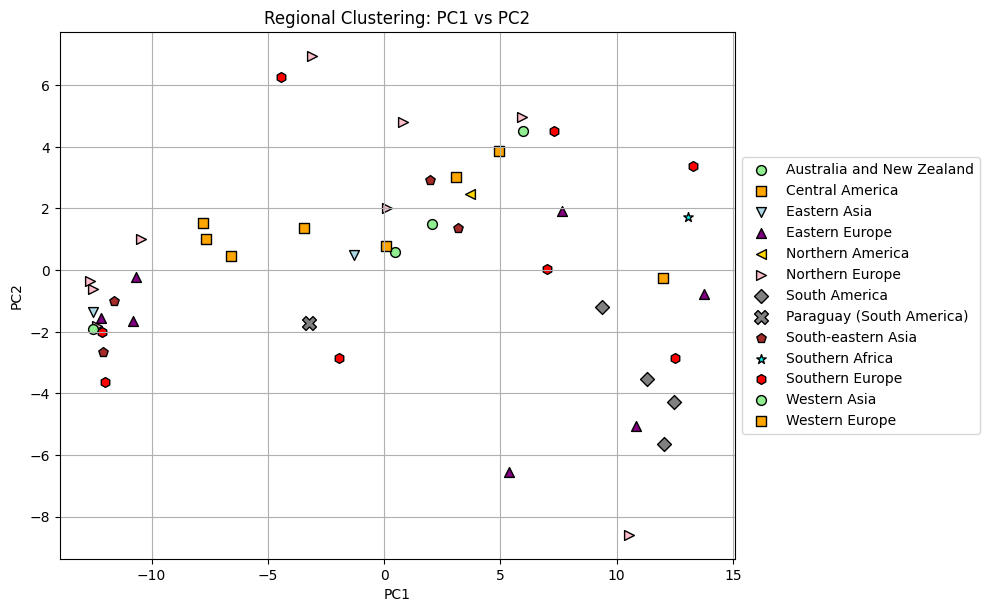

In [32]:
plot_region_clusters(target_dd, 'PC1', 'PC2')

### Plot winner cluster based

In [33]:
def plot_clusters(df, x_col, y_col, cluster_col='cluster', country_col='Country', highlight_country='Paraguay'):
    """
    Plotea un scatter plot 2D coloreando los países según su cluster.
    Los países sin cluster (NaN) se muestran en gris con transparencia.
    """
    plt.figure(figsize=(10, 6))

    # Colores para clusters definidos
    unique_clusters = sorted(df[cluster_col].dropna().unique())
    colors = ['lightgreen', 'orange', 'lightblue', 'purple', 'gold', 'pink', 'brown', 'cyan', 'red', 'olive']
    cluster_color_map = {cluster: colors[i % len(colors)] for i, cluster in enumerate(unique_clusters)}

    # Graficar países con cluster definido
    for cluster in unique_clusters:
        mask = df[cluster_col] == cluster
        highlight_mask = mask & (df[country_col] == highlight_country)
        normal_mask = mask & (df[country_col] != highlight_country)

        # Otros países
        plt.scatter(df.loc[normal_mask, x_col], df.loc[normal_mask, y_col],
                    s=50, c=cluster_color_map[cluster], marker='o',
                    edgecolor='black', label=f'Cluster {int(cluster)}')

        # Paraguay destacado
        if highlight_mask.any():
            plt.scatter(df.loc[highlight_mask, x_col], df.loc[highlight_mask, y_col],
                        s=100, c=cluster_color_map[cluster], marker='X',
                        edgecolor='black', label=f'{highlight_country} (Cluster {int(cluster)})')

    # Graficar países sin cluster
    no_cluster_mask = df[cluster_col].isna()
    if no_cluster_mask.any():
        plt.scatter(df.loc[no_cluster_mask, x_col], df.loc[no_cluster_mask, y_col],
                    s=50, c='gray', alpha=0.5, marker='o',
                    edgecolor='black', label='Sin cluster')

    plt.xlabel(x_col)
    plt.ylabel(y_col)
    plt.legend(scatterpoints=1, loc='center left', bbox_to_anchor=(1, 0.5))
    plt.grid(True)
    plt.tight_layout()
    plt.title(f'Cluster Mapping: {x_col} vs {y_col}')
    plt.show()

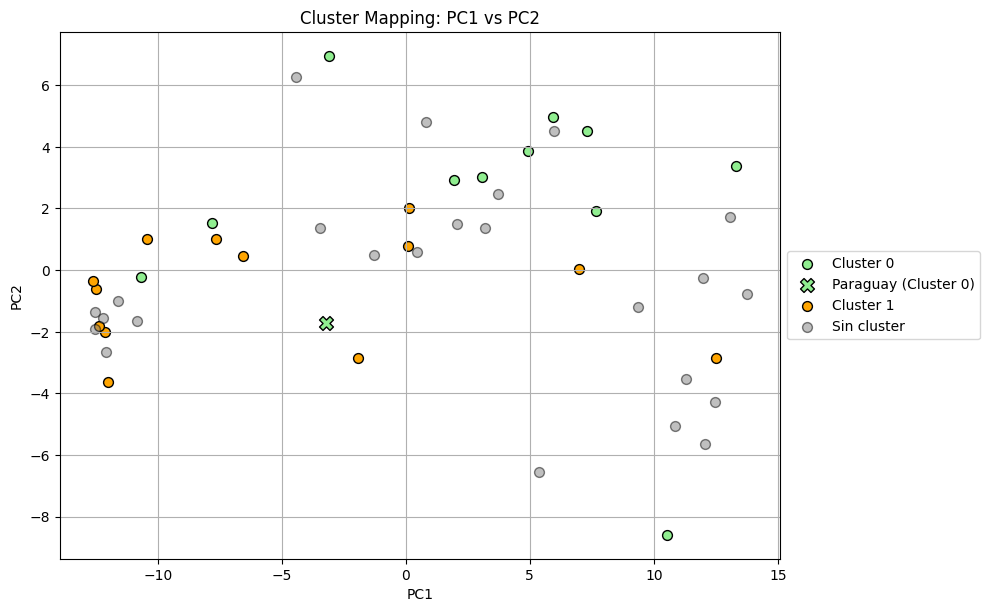

In [34]:
plot_clusters(target_dd, 'PC1', 'PC2')